# Phase 05C: ExpansionNet v2 → S1 Sequence-KD Fallback Entry

Phase 05B được giữ nguyên và kết luận Feature KD **incompatible** theo gate đã
đăng ký trước (`0.02553 < 0.05`). Notebook CPU này thực hiện đúng fallback của
Phase 05A:

- dừng nhánh Feature KD, không nới gate và không tuning alignment hậu nghiệm;
- giữ pseudo-caption corpus ExpansionNet v2 đã khóa;
- mở ablation trọng số Sequence KD trên seed 42;
- chỉ arm thắng gate seed 42 mới được xác nhận bằng seed 123/2026;
- Held-out Test luôn `SEALED`.

Hàm loss cho trọng số teacher `α`:

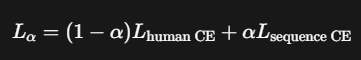

## Inputs

1. Phase 05A re-entry output.
2. Phase 05B feature compatibility output.
3. Phase 04F ExpansionNet v2 → S1 three-seed aggregate.
4. Phase 03E ExpansionNet v2 handoff.

Không cần GPU, MS COCO, model package hoặc Test data.


## Cell 1 — Environment và input discovery


In [1]:
import csv
import hashlib
import json
import os
import platform
import time
from datetime import datetime, timezone
from pathlib import Path

STARTED = time.perf_counter()
INPUT_ROOT = Path(os.environ.get("KLCN_INPUT_ROOT", "/kaggle/input"))
NOTEBOOK_ROOT = INPUT_ROOT / "notebooks" if (INPUT_ROOT / "notebooks").is_dir() else INPUT_ROOT
OUTPUT_ROOT = Path(os.environ.get(
    "KLCN_OUTPUT_ROOT",
    "/kaggle/working//phase5_teacher_a_s1_sequence_kd_fallback_entry",
))
AUDIT_DIR = OUTPUT_ROOT / "audits"
CONFIG_DIR = OUTPUT_ROOT / "configs"
RESULT_DIR = OUTPUT_ROOT / "results"
MANIFEST_DIR = OUTPUT_ROOT / "manifests"
for directory in [OUTPUT_ROOT, AUDIT_DIR, CONFIG_DIR, RESULT_DIR, MANIFEST_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

def now_utc():
    return datetime.now(timezone.utc).isoformat()

def read_json(path):
    with Path(path).open("r", encoding="utf-8") as handle:
        return json.load(handle)

def write_json(path, payload):
    path = Path(path)
    temp = path.with_suffix(path.suffix + ".tmp")
    temp.write_text(json.dumps(payload, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
    os.replace(temp, path)

def sha256_file(path, chunk_size=8 * 1024 * 1024):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        while True:
            block = handle.read(chunk_size)
            if not block:
                break
            digest.update(block)
    return digest.hexdigest()

def exactly_one(name):
    matches = sorted(NOTEBOOK_ROOT.rglob(name))
    assert len(matches) == 1, f"Cần đúng một {name}; thấy {len(matches)}: {matches}"
    return matches[0].resolve()

def resolve_inside(root, relative_path):
    root = Path(root).resolve()
    target = (root / relative_path).resolve()
    assert target.is_relative_to(root)
    return target

P5A_PATH = exactly_one("PHASE5_KD_IMPROVEMENT_REENTRY_COMPLETE.json")
P5B_PATH = exactly_one("PHASE5B_EXPANSIONNET_S1_FEATURE_PREFLIGHT_COMPLETE.json")
P5B_BLOCK_PATH = exactly_one("PHASE5C_EXPANSIONNET_S1_FEATURE_READINESS_BLOCKED.json")
P4F_PATH = exactly_one("PHASE4_TEACHER_A_S1_SEQUENCE_KD_THREE_SEED_AGGREGATE_COMPLETE.json")
P3E_PATH = exactly_one("PHASE3_TEACHER_A_EXPANSIONNET_V2_HANDOFF_COMPLETE.json")
P5A, P5B, P5B_BLOCK, P4F, P3E = map(
    read_json, [P5A_PATH, P5B_PATH, P5B_BLOCK_PATH, P4F_PATH, P3E_PATH]
)

write_json(AUDIT_DIR / "phase5c_cell01_inputs.json", {
    "schema_version": "phase5c_cell01_v1", "created_at_utc": now_utc(),
    "status": "passed", "python": platform.python_version(),
    "phase5a_found": True, "phase5b_found": True,
    "phase4f_found": True, "phase3e_found": True,
    "gpu_required": False, "dataset_read": False,
    "test_set_status": "sealed", "test_set_used": False,
    "elapsed_seconds": time.perf_counter() - STARTED,
})
print("=" * 72)
print("PHASE 05C CELL 1 STATUS")
print("=" * 72)
print("Status                    : PASSED")
print("Inputs                    : 4 / 4 FOUND")
print("GPU / dataset             : NOT REQUIRED / NOT READ")
print("Test Set status           : SEALED")
print("Progress                  : 1 / 5 code cells")
print("Next                      : verify Phase 05B decision and manifests")


PHASE 05C CELL 1 STATUS
Status                    : PASSED
Inputs                    : 4 / 4 FOUND
GPU / dataset             : NOT REQUIRED / NOT READ
Test Set status           : SEALED
Progress                  : 1 / 5 code cells
Next                      : verify Phase 05B decision and manifests


## Cell 2 — Phase 05B decision và checksum audit


In [2]:
STARTED = time.perf_counter()
assert P5A["status"] == "complete"
assert P5B["status"] == "complete_incompatible"
assert P5B["compatibility"] == "failed"
assert P5B["gradient_ratio_gate_passed"] is False
assert P5B["fp16_resource_gate_passed"] is True
assert P5B["phase05c_authorized"] is False
assert abs(float(P5B["gradient_ratio"]) - 0.025530151455657433) < 1e-15
assert P5B_BLOCK["status"] == "blocked"
assert P5B_BLOCK["full_training_authorized"] is False
for payload in [P5A, P5B, P5B_BLOCK, P4F, P3E]:
    assert payload["test_set_status"] == "sealed"
    assert payload["test_set_used"] is False

def verify_manifest(root, reference, expected_rows):
    path = resolve_inside(root, reference["relative_path"])
    assert sha256_file(path) == reference["sha256"]
    with path.open("r", encoding="utf-8", newline="") as handle:
        rows = list(csv.DictReader(handle))
    assert len(rows) == int(expected_rows)
    for row in rows:
        artifact = resolve_inside(root, row["relative_path"])
        assert artifact.is_file()
        assert artifact.stat().st_size == int(row["size_bytes"])
        assert sha256_file(artifact) == row["sha256"]
    return rows

p5b_rows = verify_manifest(P5B_PATH.parent, P5B["manifest"]["csv"], 9)
p5a_rows = verify_manifest(P5A_PATH.parent, P5A["manifest"]["csv"], P5A["manifest_rows"])
p4f_rows = verify_manifest(P4F_PATH.parent, P4F["manifest"]["csv"], P4F["manifest_rows"])
p3e_rows = verify_manifest(P3E_PATH.parent, P3E["manifest"]["csv"], 13)

write_json(AUDIT_DIR / "phase5c_cell02_integrity_fallback.json", {
    "schema_version": "phase5c_cell02_v1", "created_at_utc": now_utc(),
    "status": "passed", "phase5b_status": P5B["status"],
    "gradient_ratio": P5B["gradient_ratio"], "required_minimum": 0.05,
    "feature_branch_action": "stopped_without_training",
    "post_hoc_gate_change": False, "post_hoc_alignment_tuning": False,
    "manifest_rows_verified": len(p5a_rows)+len(p5b_rows)+len(p4f_rows)+len(p3e_rows),
    "test_set_status": "sealed", "test_set_used": False,
    "elapsed_seconds": time.perf_counter() - STARTED,
})
print("=" * 72)
print("PHASE 05C CELL 2 — FALLBACK DECISION")
print("=" * 72)
print("Phase 05B execution       : VALID")
print("Feature compatibility     : FAILED AS MEASURED")
print("Gradient ratio            :", P5B["gradient_ratio"])
print("Required minimum          : 0.05")
print("Feature branch            : STOPPED WITHOUT TRAINING")
print("Gate/alignment modified   : False / False")
print("Manifest rows verified    :", len(p5a_rows)+len(p5b_rows)+len(p4f_rows)+len(p3e_rows))
print("Progress                  : 2 / 5 code cells")
print("Next                      : lock Sequence-KD fallback evidence")


PHASE 05C CELL 2 — FALLBACK DECISION
Phase 05B execution       : VALID
Feature compatibility     : FAILED AS MEASURED
Gradient ratio            : 0.025530151455657433
Required minimum          : 0.05
Feature branch            : STOPPED WITHOUT TRAINING
Gate/alignment modified   : False / False
Manifest rows verified    : 48
Progress                  : 2 / 5 code cells
Next                      : lock Sequence-KD fallback evidence


## Cell 3 — Khóa reproduction anchor và pseudo-caption corpus


In [3]:
STARTED = time.perf_counter()
assert P4F["status"] == "complete"
assert P4F["experiment_id"] == "P4A_EXPANSIONNET_S1_SEQKD"
assert P4F["reproduction_status"] == "passed"
assert P4F["cider_gate"] == "3 / 3"
assert P4F["seeds"] == [42, 123, 2026]
assert P3E["status"] == "complete"
assert P3E["selected_method"] == "sequence_kd"
assert P3E["pseudo_caption_records"] == 113287
assert P3E["direct_logit_kd_allowed"] is False

handoff_path = resolve_inside(
    P3E_PATH.parent, "configs/teacher_a_s1_sequence_kd_handoff_contract.json"
)
handoff = read_json(handoff_path)
assert handoff["loss"]["human_caption_ce_weight"] == 0.5
assert handoff["loss"]["teacher_sequence_ce_weight"] == 0.5
assert handoff["pseudo_caption_records"] == 113287

write_json(AUDIT_DIR / "phase5c_cell03_anchor.json", {
    "schema_version": "phase5c_cell03_v1", "created_at_utc": now_utc(),
    "status": "passed", "anchor_experiment": P4F["experiment_id"],
    "anchor_teacher_weight": 0.5, "anchor_human_weight": 0.5,
    "reproduction_seeds": [42,123,2026], "cider_wins": "3 / 3",
    "pseudo_caption_records": 113287,
    "pseudo_caption_sha256": P3E["pseudo_caption_parquet_sha256"],
    "direct_logit_kd_allowed": False, "feature_kd_allowed": False,
    "test_set_status": "sealed", "test_set_used": False,
    "elapsed_seconds": time.perf_counter() - STARTED,
})
print("=" * 72)
print("PHASE 05C CELL 3 STATUS")
print("=" * 72)
print("Sequence-KD reproduction : PASSED | 3 / 3 CIDEr wins")
print("Anchor weights            : human 0.50 / teacher 0.50")
print("Pseudo-caption records    : 113287 | SHA LOCKED")
print("Logit / Feature KD        : PROHIBITED / STOPPED")
print("Progress                  : 3 / 5 code cells")
print("Next                      : pre-register weight ablation")


PHASE 05C CELL 3 STATUS
Sequence-KD reproduction : PASSED | 3 / 3 CIDEr wins
Anchor weights            : human 0.50 / teacher 0.50
Pseudo-caption records    : 113287 | SHA LOCKED
Logit / Feature KD        : PROHIBITED / STOPPED
Progress                  : 3 / 5 code cells
Next                      : pre-register weight ablation


## Cell 4 — Pre-register Sequence-KD weight ablation


In [4]:
STARTED = time.perf_counter()
arms = [
    {"arm":"R0","human_weight":1.00,"teacher_weight":0.00,"source":"Phase 2 S1 baseline","new_training":False},
    {"arm":"R1","human_weight":0.50,"teacher_weight":0.50,"source":"Phase 4 reproduction","new_training":False},
    {"arm":"R2","human_weight":0.75,"teacher_weight":0.25,"source":"low-teacher fallback candidate","new_training":True},
    {"arm":"R3","human_weight":0.25,"teacher_weight":0.75,"source":"high-teacher fallback candidate","new_training":True},
]
assert all(abs(x["human_weight"] + x["teacher_weight"] - 1.0) < 1e-12 for x in arms)
contract = {
    "schema_version": "phase5c_sequence_kd_weight_ablation_v1",
    "created_at_utc": now_utc(), "status": "locked",
    "teacher": "ExpansionNet v2 pretrained", "student": "S1 MobileNetV3-Large",
    "formula": "L_alpha=(1-alpha)*L_human_CE + alpha*L_sequence_CE",
    "arms": arms, "screening_seed": 42,
    "confirmation_seeds": [123, 2026],
    "screening_policy": "Run R2 and R3 independently from the same seed-42 initialization.",
    "selection_split": "Karpathy Validation only",
    "primary_metric": "CIDEr-D",
    "tie_break_order": ["BLEU-4 higher", "validation CE lower", "earlier epoch"],
    "gate_vs_r1": {
        "cider_delta_minimum": 0.001,
        "bleu4_non_regression_tolerance": -0.002
    },
    "confirmation_policy": "Only the best seed-42 arm passing the gate may run seeds 123 and 2026.",
    "if_both_fail": "Stop Phase 5 Sequence-KD improvement; retain R1 reproduction.",
    "pseudo_caption_corpus_changed": False,
    "architecture_changed": False, "optimizer_schedule_changed": False,
    "feature_kd": False, "direct_logit_kd": False,
    "test_set_status": "sealed", "test_set_used": False,
}
CONTRACT_PATH = CONFIG_DIR / "phase5c_sequence_kd_weight_ablation_contract.json"
write_json(CONTRACT_PATH, contract)
matrix_path = CONFIG_DIR / "phase5c_sequence_kd_weight_ablation_matrix.csv"
with matrix_path.open("w", encoding="utf-8", newline="") as handle:
    writer = csv.DictWriter(handle, fieldnames=list(arms[0]))
    writer.writeheader()
    writer.writerows(arms)

write_json(AUDIT_DIR / "phase5c_cell04_preregistration.json", {
    "schema_version": "phase5c_cell04_v1", "created_at_utc": now_utc(),
    "status": "passed", "arms": ["R0","R1","R2","R3"],
    "new_seed42_runs": ["R2","R3"], "validation_gate_locked": True,
    "confirmation_before_screening": False,
    "test_set_status": "sealed", "test_set_used": False,
    "elapsed_seconds": time.perf_counter() - STARTED,
})
print("=" * 72)
print("PHASE 05C CELL 4 — LOCKED ABLATION")
print("=" * 72)
for arm in arms:
    print(arm["arm"], "| human", arm["human_weight"], "| teacher", arm["teacher_weight"], "| new", arm["new_training"])
print("Screening seed            : 42")
print("Gate vs R1                : CIDEr +0.001; BLEU-4 >= -0.002")
print("Confirmation seeds        : 123 / 2026 only after seed-42 pass")
print("Progress                  : 4 / 5 code cells")
print("Next                      : package and authorize Phase 05D readiness")


PHASE 05C CELL 4 — LOCKED ABLATION
R0 | human 1.0 | teacher 0.0 | new False
R1 | human 0.5 | teacher 0.5 | new False
R2 | human 0.75 | teacher 0.25 | new True
R3 | human 0.25 | teacher 0.75 | new True
Screening seed            : 42
Gate vs R1                : CIDEr +0.001; BLEU-4 >= -0.002
Confirmation seeds        : 123 / 2026 only after seed-42 pass
Progress                  : 4 / 5 code cells
Next                      : package and authorize Phase 05D readiness


## Cell 5 — Manifest, completion marker và Phase 05D authorization


In [5]:
STARTED = time.perf_counter()
artifact_files = sorted(AUDIT_DIR.glob("*.json")) + sorted(CONFIG_DIR.glob("*"))
rows = []
for path in artifact_files:
    rows.append({
        "relative_path": path.relative_to(OUTPUT_ROOT).as_posix(),
        "size_bytes": path.stat().st_size, "sha256": sha256_file(path),
    })
MANIFEST_PATH = MANIFEST_DIR / "phase5c_sequence_kd_fallback_manifest.csv"
with MANIFEST_PATH.open("w", encoding="utf-8", newline="") as handle:
    writer = csv.DictWriter(handle, fieldnames=["relative_path","size_bytes","sha256"])
    writer.writeheader(); writer.writerows(rows)
SHA_PATH = MANIFEST_DIR / "SHA256SUMS"
SHA_PATH.write_text("".join(f"{r['sha256']}  {r['relative_path']}\n" for r in rows), encoding="utf-8")

AUTH_PATH = OUTPUT_ROOT / "PHASE5D_SEQUENCE_KD_WEIGHT_ABLATION_READINESS_AUTHORIZED.json"
write_json(AUTH_PATH, {
    "schema_version": "phase5d_sequence_kd_weight_ablation_readiness_authorized_v1",
    "created_at_utc": now_utc(), "status": "authorized",
    "authorized_next": "Phase 05D production readiness for R2/R3 seed 42",
    "contract": {
        "relative_path": CONTRACT_PATH.relative_to(OUTPUT_ROOT).as_posix(),
        "sha256": sha256_file(CONTRACT_PATH),
    },
    "full_training_authorized": False, "allowed_seed": 42,
    "test_set_status": "sealed", "test_set_used": False,
})
MARKER_PATH = OUTPUT_ROOT / "PHASE5C_SEQUENCE_KD_FALLBACK_ENTRY_COMPLETE.json"
write_json(MARKER_PATH, {
    "schema_version": "phase5c_sequence_kd_fallback_entry_complete_v1",
    "created_at_utc": now_utc(), "status": "complete",
    "feature_branch": "stopped_incompatible",
    "fallback_method": "Sequence-KD teacher-weight ablation",
    "new_seed42_arms": ["R2","R3"],
    "phase05d_authorized": True,
    "next_marker": {
        "relative_path": AUTH_PATH.relative_to(OUTPUT_ROOT).as_posix(),
        "sha256": sha256_file(AUTH_PATH),
    },
    "manifest": {
        "csv": {"relative_path": MANIFEST_PATH.relative_to(OUTPUT_ROOT).as_posix(), "sha256": sha256_file(MANIFEST_PATH), "rows": len(rows)},
        "sha256sums": {"relative_path": SHA_PATH.relative_to(OUTPUT_ROOT).as_posix(), "sha256": sha256_file(SHA_PATH)},
    },
    "full_training_started": False,
    "test_set_status": "sealed", "test_set_used": False,
})
print("=" * 72)
print("PHASE 05C FINAL STATUS")
print("=" * 72)
print("Status                    : COMPLETE")
print("Feature branch            : STOPPED — INCOMPATIBLE")
print("Fallback                  : SEQUENCE-KD WEIGHT ABLATION")
print("R2 / R3 seed 42           : PRE-REGISTERED")
print("Phase 05D readiness       : AUTHORIZED")
print("Full training started     : False")
print("Manifest rows             :", len(rows))
print("Test Set status           : SEALED")
print("Progress                  : 5 / 5 code cells")
print("Next                      : Phase 05D production readiness for R2/R3")


PHASE 05C FINAL STATUS
Status                    : COMPLETE
Feature branch            : STOPPED — INCOMPATIBLE
Fallback                  : SEQUENCE-KD WEIGHT ABLATION
R2 / R3 seed 42           : PRE-REGISTERED
Phase 05D readiness       : AUTHORIZED
Full training started     : False
Manifest rows             : 6
Test Set status           : SEALED
Progress                  : 5 / 5 code cells
Next                      : Phase 05D production readiness for R2/R3
